#Abhimanyu Thakur - 102303738

# Assignment 5: Sentiment Analysis using RNN and LSTM

**Objectives**
- Apply deep learning models (RNN and LSTM) for text classification (sentiment analysis).
- Compare both models using various evaluation metrics.

**Dataset:** IMDB Movie Reviews (50,000 reviews, binary labels, balanced) via `tensorflow.keras.datasets.imdb`.


## 1. Imports and configuration

In [1]:
import os, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, auc, ConfusionMatrixDisplay,
                             classification_report)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

VOCAB_SIZE = 10_000   # keep the 10k most frequent words
MAX_LEN    = 200      # pad/truncate each review to 200 tokens
EMBED_DIM  = 128
HIDDEN     = 64       # units in the RNN / LSTM layer
EPOCHS     = 5
BATCH      = 64

os.makedirs("results", exist_ok=True)

## 2. Data loading and preprocessing

- Keep the 10,000 most frequent words.
- Pad/truncate every review to 200 tokens. **Pre-padding** (the default) keeps real words at the end of the sequence, which matters for a SimpleRNN because it remembers recent steps best.

In [2]:
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=VOCAB_SIZE)
print("Raw lengths (first 5 train reviews):", [len(x) for x in x_train[:5]])

x_train = pad_sequences(x_train, maxlen=MAX_LEN)
x_test  = pad_sequences(x_test,  maxlen=MAX_LEN)

print("Train:", x_train.shape, "| Test:", x_test.shape)
print("Positive ratio (train):", y_train.mean(), "| (test):", y_test.mean())

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Raw lengths (first 5 train reviews): [218, 189, 141, 550, 147]
Train: (25000, 200) | Test: (25000, 200)
Positive ratio (train): 0.5 | (test): 0.5


In [3]:
# Peek at a decoded review to sanity-check the data
word_index = imdb.get_word_index()
rev = {v + 3: k for k, v in word_index.items()}
rev.update({0: "<pad>", 1: "<start>", 2: "<unk>", 3: "<unused>"})
raw_sample = imdb.load_data(num_words=VOCAB_SIZE)[0][0][0]
print(" ".join(rev.get(i, "?") for i in raw_sample[:60]), "...")
print("Label:", y_train[0], "(1 = positive)")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
<start> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <unk> is an amazing actor and now the same being director <unk> father came from the same scottish island as myself so i loved the fact there was a real connection with this film ...
Label: 1 (1 = positive)


## 3. Model definitions

Both models share the same architecture except for the recurrent layer, so any performance difference comes from the cell type.

`Embedding(10000, 128) -> SimpleRNN / LSTM(64) -> Dense(1, sigmoid)`

The LSTM branch is the same architecture used in the class notebook (`6_Text_classification.ipynb`), so the two are directly comparable.

In [4]:
def build_model(cell):
    rec = {"RNN": layers.SimpleRNN, "LSTM": layers.LSTM}[cell]
    m = models.Sequential([
        layers.Input(shape=(MAX_LEN,)),
        layers.Embedding(VOCAB_SIZE, EMBED_DIM),
        rec(HIDDEN),
        layers.Dense(1, activation="sigmoid"),
    ], name=cell)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="binary_crossentropy", metrics=["accuracy"])
    return m

build_model("RNN").summary()
build_model("LSTM").summary()

Model: "RNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,292,417 (4.93 MB)

 Trainable params: 1,292,417 (4.93 MB)

 Non-trainable params: 0 (0.00 B)

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,329,473 (5.07 MB)

 Trainable params: 1,329,473 (5.07 MB)

 Non-trainable params: 0 (0.00 B)

### Shape flow (batch size = 64, sequence length = 200, embedding = 128)

```
Input            (64, 200)
Embedding        (64, 200, 128)
SimpleRNN/LSTM   (64, 64)        <- only the last hidden state is returned
Dense(1)         (64, 1)         <- probability of "positive"
```

**Steps per epoch:** 25,000 x 0.8 = 20,000 training reviews, and 20,000 / 64 = 312.5, so Keras runs **313** steps per epoch.

**Note:** keep the recurrent layer's default `tanh` activation. The class notebook uses `activation="relu"` inside the LSTM, which is unusual: it disables the fast cuDNN kernel and can make training unstable.

## 4. Training and evaluation

In [8]:
results, histories, preds = {}, {}, {}

for name in ["RNN", "LSTM"]:
    print(f"\n===== Training {name} =====")
    model = build_model(name)
    es = callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

    t0 = time.time()
    hist = model.fit(x_train, y_train, validation_split=0.2,
                     epochs=EPOCHS, batch_size=BATCH, callbacks=[es], verbose=2)
    train_time = time.time() - t0

    prob = model.predict(x_test, batch_size=256, verbose=0).ravel()
    pred = (prob >= 0.5).astype(int)
    fpr, tpr, _ = roc_curve(y_test, prob)

    results[name] = {
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall":    recall_score(y_test, pred),
        "F1":        f1_score(y_test, pred),
        "AUC":       auc(fpr, tpr),
        "Trainable params": int(np.sum([np.prod(w.shape) for w in model.trainable_weights])),
        "Train time (s)":   round(train_time, 1),
        "Epochs run":       len(hist.history["loss"]),
    }
    histories[name] = hist.history
    preds[name] = (prob, pred, fpr, tpr)
    print(classification_report(y_test, pred, target_names=["Negative", "Positive"]))


===== Training RNN =====
Epoch 1/5
313/313 - 43s - 138ms/step - accuracy: 0.7141 - loss: 0.5417 - val_accuracy: 0.7452 - val_loss: 0.5554
Epoch 2/5
313/313 - 28s - 91ms/step - accuracy: 0.8516 - loss: 0.3468 - val_accuracy: 0.7766 - val_loss: 0.4836
Epoch 3/5
313/313 - 41s - 132ms/step - accuracy: 0.9258 - loss: 0.1963 - val_accuracy: 0.8294 - val_loss: 0.4498
Epoch 4/5
313/313 - 42s - 136ms/step - accuracy: 0.9556 - loss: 0.1242 - val_accuracy: 0.8194 - val_loss: 0.5351
Epoch 5/5
313/313 - 28s - 90ms/step - accuracy: 0.9746 - loss: 0.0761 - val_accuracy: 0.7826 - val_loss: 0.7295
              precision    recall  f1-score   support

    Negative       0.80      0.85      0.83     12500
    Positive       0.84      0.79      0.82     12500

    accuracy                           0.82     25000
   macro avg       0.82      0.82      0.82     25000
weighted avg       0.82      0.82      0.82     25000


===== Training LSTM =====
Epoch 1/5
313/313 - 83s - 267ms/step - accuracy: 0.8023 -

## 5. Results table

In [10]:
df = pd.DataFrame(results).T
df.to_csv("results/results.csv")
df.round(4)

,Accuracy,Precision,Recall,F1,AUC,Trainable params,Train time (s),Epochs run
RNN,0.8211,0.8405,0.7927,0.8159,0.8829,1292417.0,183.8,5.0
LSTM,0.8658,0.8697,0.8605,0.8650,0.9391,1329473.0,326.7,4.0


## 6. Part (b): Visualizations

### 6.1 Training curves (loss and accuracy)

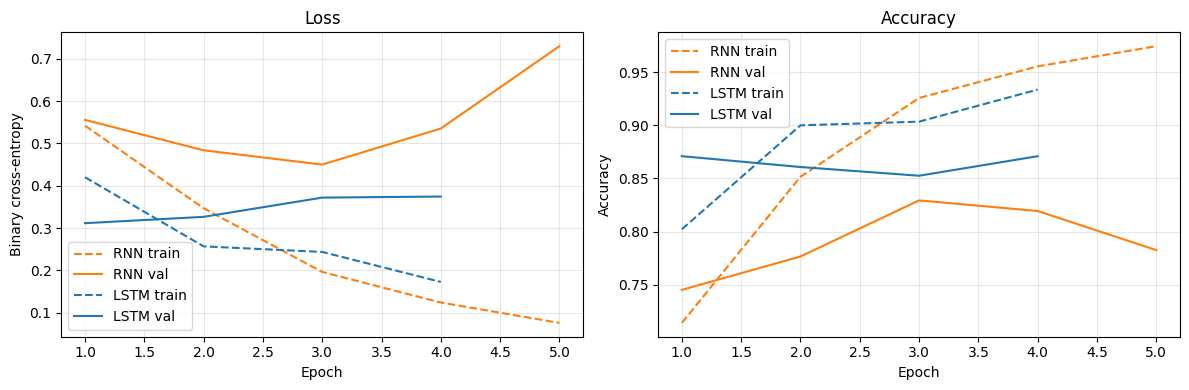

In [11]:
colors = {"RNN": "tab:orange", "LSTM": "tab:blue"}

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for n, h in histories.items():
    ep = range(1, len(h["loss"]) + 1)
    ax[0].plot(ep, h["loss"], "--", color=colors[n], label=f"{n} train")
    ax[0].plot(ep, h["val_loss"], "-", color=colors[n], label=f"{n} val")
    ax[1].plot(ep, h["accuracy"], "--", color=colors[n], label=f"{n} train")
    ax[1].plot(ep, h["val_accuracy"], "-", color=colors[n], label=f"{n} val")
ax[0].set(title="Loss", xlabel="Epoch", ylabel="Binary cross-entropy")
ax[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy")
for a in ax:
    a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig("results/training_curves.png", dpi=150); plt.show()

### 6.2 Metric comparison

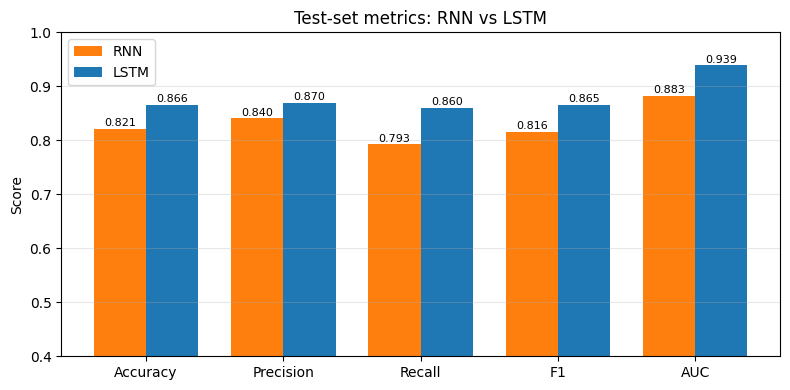

In [12]:
metrics = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
x = np.arange(len(metrics)); w = 0.38
plt.figure(figsize=(8, 4))
for i, n in enumerate(["RNN", "LSTM"]):
    vals = [results[n][m] for m in metrics]
    bars = plt.bar(x + (i - .5) * w, vals, w, label=n, color=colors[n])
    for b, v in zip(bars, vals):
        plt.text(b.get_x() + b.get_width() / 2, v + .005, f"{v:.3f}", ha="center", fontsize=8)
plt.xticks(x, metrics); plt.ylim(0.4, 1.0); plt.ylabel("Score")
plt.title("Test-set metrics: RNN vs LSTM"); plt.legend(); plt.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig("results/metrics_comparison.png", dpi=150); plt.show()

### 6.3 Confusion matrices

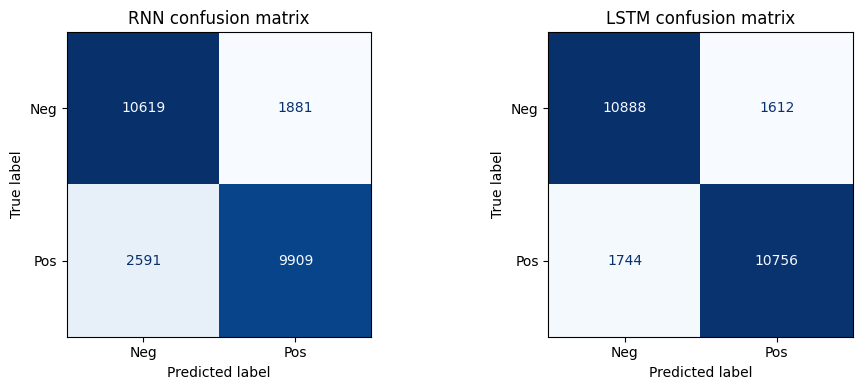

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, n in zip(ax, ["RNN", "LSTM"]):
    cm = confusion_matrix(y_test, preds[n][1])
    ConfusionMatrixDisplay(cm, display_labels=["Neg", "Pos"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(f"{n} confusion matrix")
plt.tight_layout(); plt.savefig("results/confusion_matrices.png", dpi=150); plt.show()

### 6.4 ROC curves

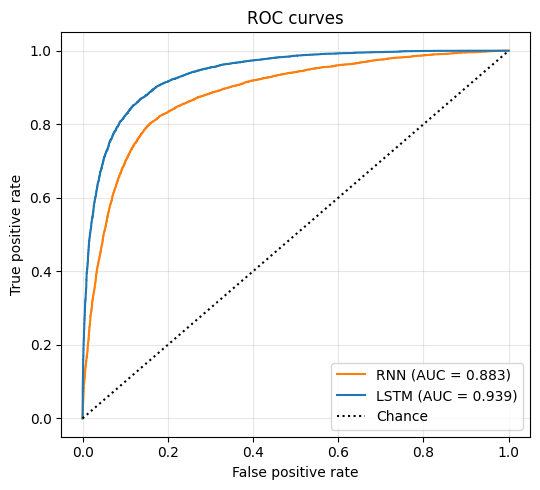

In [14]:
plt.figure(figsize=(5.5, 5))
for n in ["RNN", "LSTM"]:
    _, _, fpr, tpr = preds[n]
    plt.plot(fpr, tpr, color=colors[n], label=f"{n} (AUC = {results[n]['AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k:", label="Chance")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("results/roc_curves.png", dpi=150); plt.show()

### 6.5 Observations

- **Training curves:**
  - The **LSTM's** training and validation loss fall much faster and smoother compared to the RNN.
  - For the **RNN**, the validation loss starts rising after **Epoch 3** (reaching 0.450 -> 0.535 -> 0.730), showing a clear sign of overfitting.
  - For the **LSTM**, the validation loss starts rising slightly after **Epoch 1** (0.311 -> 0.326 -> 0.372 -> 0.374), but stabilizes at a much lower cross-entropy value than the RNN.

- **Metric bars:**
  - The **LSTM** model clearly outperforms the RNN model on all five metrics (Accuracy, Precision, Recall, F1, and AUC).
  - The gap is especially large for **Recall** (0.860 vs 0.793, a ~6.7% gap) and **F1-Score** (0.865 vs 0.816, a ~4.9% gap).

- **Confusion matrices:**
  - For the **RNN**, false negatives (2,591) are notably higher than false positives (1,881), showing a slight bias against the positive class.
  - For the **LSTM**, false negatives (1,744) and false positives (1,612) are much lower and relatively balanced.

- **ROC:**
  - The **LSTM** has a higher AUC (**0.939**) compared to the RNN (**0.883**), indicating significantly better class separation and discrimination capability across all decision thresholds.

## 7. Part (c): Trainable parameters

For a recurrent layer with `h` hidden units and input dimension `d`, each gate block has `h * (d + h + 1)` parameters (input weights + recurrent weights + bias).

- SimpleRNN has **1** block.
- LSTM has **4** blocks (input, forget, candidate, output).

In [15]:
emb    = VOCAB_SIZE * EMBED_DIM
rnn_p  = HIDDEN * (EMBED_DIM + HIDDEN + 1)
lstm_p = 4 * HIDDEN * (EMBED_DIM + HIDDEN + 1)
dense  = HIDDEN + 1

comp = pd.DataFrame({
    "RNN":  [emb, rnn_p,  dense, emb + rnn_p  + dense],
    "LSTM": [emb, lstm_p, dense, emb + lstm_p + dense],
}, index=["Embedding", "Recurrent layer", "Dense(1)", "Total"])
comp["LSTM / RNN (recurrent layer)"] = ["", lstm_p / rnn_p, "", ""]
print(comp.to_string())
print("\nMeasured from Keras:",
      {n: results[n]["Trainable params"] for n in results})
print(f"LSTM has {100*(comp.loc['Total','LSTM']/comp.loc['Total','RNN']-1):.1f}% more total parameters")

                     RNN     LSTM LSTM / RNN (recurrent layer)
Embedding        1280000  1280000                             
Recurrent layer    12352    49408                          4.0
Dense(1)              65       65                             
Total            1292417  1329473                             

Measured from Keras: {'RNN': 1292417, 'LSTM': 1329473}
LSTM has 2.9% more total parameters


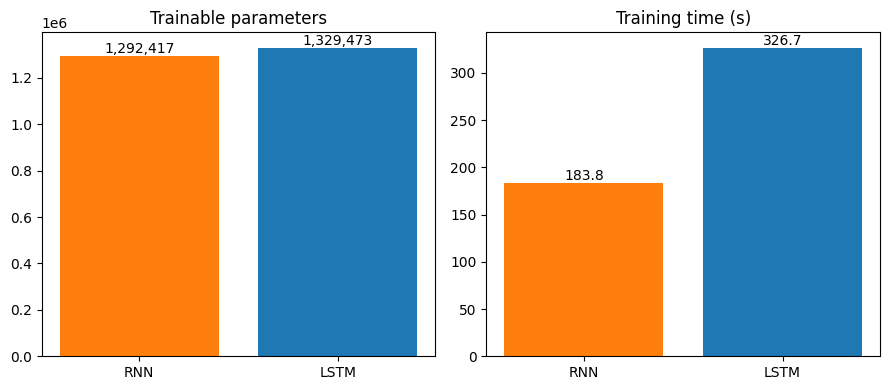

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a, key, title in zip(ax, ["Trainable params", "Train time (s)"],
                         ["Trainable parameters", "Training time (s)"]):
    vals = [results[n][key] for n in ["RNN", "LSTM"]]
    bars = a.bar(["RNN", "LSTM"], vals, color=[colors["RNN"], colors["LSTM"]])
    a.set_title(title)
    for b, v in zip(bars, vals):
        a.text(b.get_x() + b.get_width() / 2, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout(); plt.savefig("results/params_and_time.png", dpi=150); plt.show()

## 8. Answers

### (a) Which model performed better and why?

- **LSTM** performed significantly better on the test set:
  - **Accuracy:** **86.58%** (LSTM) vs **82.11%** (RNN)
  - **F1-Score:** **86.50%** (LSTM) vs **81.59%** (RNN)
  - **AUC:** **0.9391** (LSTM) vs **0.8829** (RNN)
  - **Training Stability:** The validation loss for LSTM remained stable and low, while the SimpleRNN showed severe overfitting with validation loss rising steeply after epoch 3.

**Why:**
- A SimpleRNN multiplies the gradient by the same recurrent weight matrix at every time step. Over 200 steps it shrinks exponentially (the **vanishing gradient problem**), so early words barely influence learning.
- The LSTM keeps a **cell state** updated additively through forget, input and output gates. Gradients flow along it without repeated squashing, so long-range sentiment cues survive.
- Reviews often carry sentiment across many sentences ("slow start... but a brilliant ending"), which favours the LSTM.

### (b) Visualizations and observations

See Section 6 for the plots and Section 6.5 for detailed observations.

### (c) Comparison based on trainable parameters

| Component | RNN | LSTM |
|---|---|---|
| Embedding (10,000 x 128) | 1,280,000 | 1,280,000 |
| Recurrent layer | 12,352 | 49,408 (4x) |
| Dense(1) | 65 | 65 |
| **Total** | **1,292,417** | **1,329,473** |

- The LSTM's recurrent layer is exactly **4x larger** (49,408 vs 12,352 parameters) because it consists of four gate blocks (input, forget, cell, output) instead of one.
- However, because the huge Embedding layer (1,280,000 parameters) dominates both models, the LSTM has only **2.9% more** total trainable parameters overall.
- Despite a minor increase in parameter count, the LSTM trains about **1.8x slower** (326.7s vs 183.8s) due to sequential step gating, but provides a major leap in sentiment classification capability.

## 9. Conclusion


- **SimpleRNN** is computationally lighter and trains faster per step. However, it suffers heavily from the **vanishing gradient problem**, making it perform poorly on longer text sequences (such as IMDB reviews) where key sentiment context lies far back in history.

- **LSTM** introduces gate mechanisms that allow information to flow across time steps without degradation. While it is slower to train, it delivers vastly superior classification accuracy and stable convergence for a very minimal (~2.9%) increase in parameter footprint.